# 03. Q1 고객 불만의 주요 원인

**질문**: 고객 불만의 주요 원인은 무엇인가?

- 데이터: MySQL `review_complaint_labels`(LLM 분류 결과, 텍스트 있는 1~3점 리뷰 14,286건)와 `order_reviews`·`orders`·`v_orders`
- 쿼리: `sql/analysis/q1_*.sql` 파일을 읽어서 실행한다(노트북에 SQL을 직접 쓰지 않음)
- 차트: `reports/figures/q1_*.png`로 저장
- 결과 정리: `reports/analysis/q1_complaint_causes.md`

**해석 주의**: 분석 대상은 텍스트가 있는 1~3점 리뷰뿐이다(전체 리뷰의 약 14%). 분류 정확도는 검증 100건 기준 라벨 조합 완전 일치율 0.78, 주 원인 kappa 0.86이다.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sqlalchemy import text


def find_project_root(start: Path) -> Path:
    """sql/analysis 폴더가 있는 프로젝트 루트를 찾는다."""
    for path in [start, *start.parents]:
        if (path / "sql" / "analysis").is_dir():
            return path
    raise FileNotFoundError("프로젝트 루트를 찾지 못함")


ROOT = find_project_root(Path.cwd())
SQL_DIR = ROOT / "sql" / "analysis"
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT / "src" / "etl"))
from db import get_engine  # noqa: E402

engine = get_engine()

# 한글 폰트 (Windows: Malgun Gothic), 마이너스 기호 깨짐 방지
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)

LABEL_KO = {
    "NOT_RECEIVED": "미수령", "WRONG_MISSING": "오배송·누락", "DAMAGED": "파손·불량",
    "NOT_AS_DESCRIBED": "설명 불일치", "LOW_QUALITY": "품질 불만", "SHIPPING_COST": "배송비·수령 불편",
    "DELAY": "배송 지연", "SERVICE": "응대·환불", "OTHER": "기타", "UNCLEAR": "판단 불가", "NO_COMPLAINT": "불만 없음",
}
OWNER_ORDER = ["물류", "판매자 출고", "상품", "판매자 응대", "플랫폼 정책", "기타", "불만 없음"]
OWNER_COLORS = dict(zip(OWNER_ORDER, ["#d62728", "#ff7f0e", "#1f77b4", "#9467bd", "#8c564b", "#7f7f7f", "#2ca02c"]))


def run_sql(name: str) -> pd.DataFrame:
    """sql/analysis의 SQL 파일을 실행해 DataFrame으로 돌려준다."""
    return pd.read_sql(text((SQL_DIR / name).read_text(encoding="utf-8")), engine)


def pct(df: pd.DataFrame, cols: list[str]) -> pd.DataFrame:
    """비율 컬럼을 % 문자열로 바꾼 표시용 사본을 만든다."""
    out = df.copy()
    for c in cols:
        out[c] = (out[c].astype(float) * 100).map("{:.1f}%".format)
    return out


def save(fig, name: str) -> None:
    """차트를 reports/figures에 저장한다."""
    fig.savefig(FIG_DIR / name, bbox_inches="tight")
    print(f"저장: reports/figures/{name}")

## 1. 불만 유형별 비중

- **다중 라벨 비율**: 해당 유형이 붙은 리뷰 / 전체 리뷰 (한 리뷰에 여러 유형이 붙을 수 있어 합이 100%를 넘음)
- **주 원인 비율**: 우선순위로 고른 주 원인 1개 기준 (합 100%)

DELAY·SERVICE처럼 다른 불만과 함께 붙는 부가 유형은 두 기준의 차이가 크다.

,유형,label,n_multi,share_multi,n_primary,share_primary
0,미수령,NOT_RECEIVED,3604.0,25.2%,3604.0,25.2%
1,오배송·누락,WRONG_MISSING,3277.0,22.9%,3210.0,22.5%
2,파손·불량,DAMAGED,1463.0,10.2%,1362.0,9.5%
3,설명 불일치,NOT_AS_DESCRIBED,1414.0,9.9%,1221.0,8.6%
4,품질 불만,LOW_QUALITY,1234.0,8.6%,983.0,6.9%
5,배송비·수령 불편,SHIPPING_COST,467.0,3.3%,347.0,2.4%
6,배송 지연,DELAY,3103.0,21.7%,1233.0,8.6%
7,응대·환불,SERVICE,2747.0,19.2%,809.0,5.7%
8,기타,OTHER,397.0,2.8%,232.0,1.6%
9,판단 불가,UNCLEAR,279.0,1.9%,279.0,1.9%


저장: reports/figures/q1_type_share.png


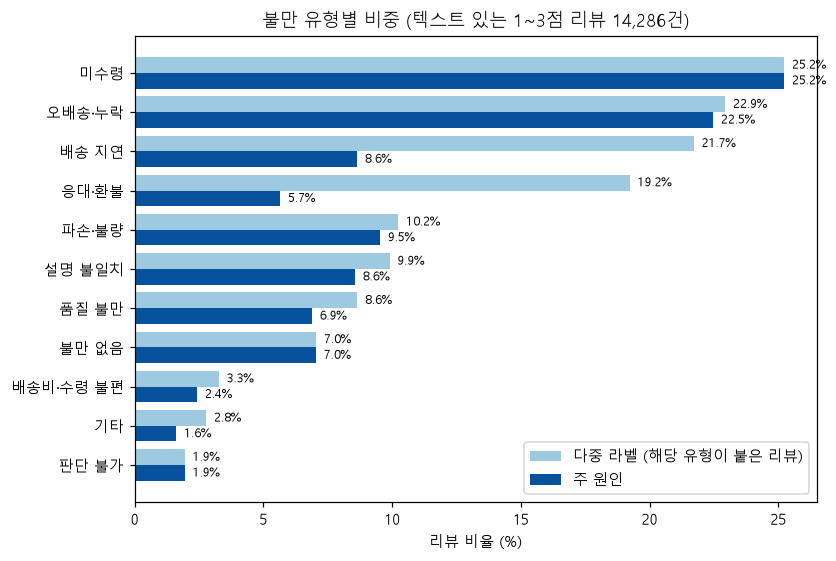

In [2]:
type_share = run_sql("q1_01_type_share.sql")
type_share["유형"] = type_share["label"].map(LABEL_KO)
overall = type_share[type_share["score_group"] == "전체"].copy()
display(pct(overall[["유형", "label", "n_multi", "share_multi", "n_primary", "share_primary"]], ["share_multi", "share_primary"]))

plot_df = overall.sort_values("share_multi")
fig, ax = plt.subplots(figsize=(8, 5.5))
y = range(len(plot_df))
ax.barh([i + 0.2 for i in y], plot_df["share_multi"] * 100, height=0.4, label="다중 라벨 (해당 유형이 붙은 리뷰)", color="#9ecae1")
ax.barh([i - 0.2 for i in y], plot_df["share_primary"] * 100, height=0.4, label="주 원인", color="#08519c")
ax.set_yticks(list(y), plot_df["유형"])
ax.set_xlabel("리뷰 비율 (%)")
ax.set_title(f"불만 유형별 비중 (텍스트 있는 1~3점 리뷰 {int(overall['n_reviews'].iloc[0]):,}건)")
for i, (m, p) in enumerate(zip(plot_df["share_multi"], plot_df["share_primary"])):
    ax.text(m * 100 + 0.3, i + 0.2, f"{m:.1%}", va="center", fontsize=8)
    ax.text(p * 100 + 0.3, i - 0.2, f"{p:.1%}", va="center", fontsize=8)
ax.legend(loc="lower right")
save(fig, "q1_type_share.png")
plt.show()

### 리뷰 점수별 유형 비중 (주 원인 기준)

점수가 낮을수록 어떤 유형이 많아지는지 본다. 3점 리뷰에는 불만 없음·품질 불만이, 1점 리뷰에는 미수령이 많을 것으로 예상된다.

In [3]:
by_score = type_share[type_share["score_group"] != "전체"]
score_n = by_score.groupby("score_group")["n_reviews"].first()
print("점수별 리뷰 수:", {f"{k}점": int(v) for k, v in score_n.items()})
pivot = by_score.pivot(index="유형", columns="score_group", values="share_primary").reindex(overall["유형"])
pivot.columns = [f"{c}점" for c in pivot.columns]
display((pivot * 100).round(1).astype(str) + "%")
pivot_multi = by_score.pivot(index="유형", columns="score_group", values="share_multi").reindex(overall["유형"])
pivot_multi.columns = [f"{c}점 (다중)" for c in pivot_multi.columns]
display((pivot_multi * 100).round(1).astype(str) + "%")

점수별 리뷰 수: {'1점': 8640, '2점': 2118, '3점': 3528}


,1점,2점,3점
유형,,,
미수령,34.6%,15.9%,7.8%
오배송·누락,24.6%,25.0%,15.8%
파손·불량,8.6%,12.1%,10.3%
설명 불일치,7.6%,10.8%,9.6%
품질 불만,4.2%,9.8%,11.7%
배송비·수령 불편,1.4%,3.2%,4.4%
배송 지연,7.5%,10.9%,10.0%
응대·환불,7.2%,3.9%,2.9%
기타,0.8%,2.0%,3.3%


,1점 (다중),2점 (다중),3점 (다중)
유형,,,
미수령,34.6%,15.9%,7.8%
오배송·누락,25.1%,25.4%,16.0%
파손·불량,9.5%,12.8%,10.6%
설명 불일치,9.2%,12.0%,10.4%
품질 불만,6.0%,11.8%,13.2%
배송비·수령 불편,2.5%,3.6%,5.0%
배송 지연,24.9%,21.1%,14.2%
응대·환불,26.0%,12.8%,6.5%
기타,2.1%,3.3%,4.2%


## 2. 개선 주체별 비중

유형을 개선 책임이 있는 주체로 묶는다.

| 주체 | 유형 |
|---|---|
| 물류 | 미수령, 배송 지연 |
| 판매자 출고 | 오배송·누락 |
| 상품 | 파손·불량, 설명 불일치, 품질 불만 |
| 판매자 응대 | 응대·환불 |
| 플랫폼 정책 | 배송비·수령 불편 |
| 기타 | 기타, 판단 불가 |

,owner,n_any,share_any,n_primary,share_primary
0,물류,5081.0,35.6%,4837.0,33.9%
1,판매자 출고,3277.0,22.9%,3210.0,22.5%
2,상품,3775.0,26.4%,3566.0,25.0%
3,판매자 응대,2747.0,19.2%,809.0,5.7%
4,플랫폼 정책,467.0,3.3%,347.0,2.4%
5,기타,676.0,4.7%,511.0,3.6%
6,불만 없음,1007.0,7.0%,1006.0,7.0%


저장: reports/figures/q1_owner_share.png


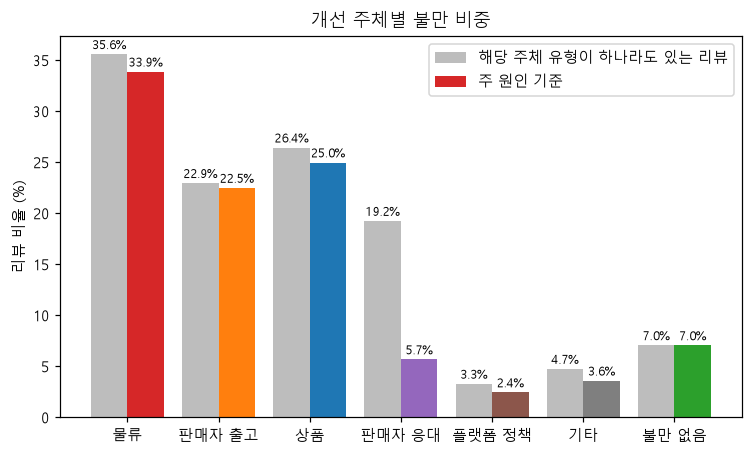

In [4]:
owner_share = run_sql("q1_02_owner_share.sql")
display(pct(owner_share[["owner", "n_any", "share_any", "n_primary", "share_primary"]], ["share_any", "share_primary"]))

fig, ax = plt.subplots(figsize=(8, 4.5))
x = range(len(owner_share))
ax.bar([i - 0.2 for i in x], owner_share["share_any"] * 100, width=0.4, label="해당 주체 유형이 하나라도 있는 리뷰", color="#bdbdbd")
ax.bar([i + 0.2 for i in x], owner_share["share_primary"] * 100, width=0.4, label="주 원인 기준",
       color=[OWNER_COLORS[o] for o in owner_share["owner"]])
for i, (a, p) in enumerate(zip(owner_share["share_any"], owner_share["share_primary"])):
    ax.text(i - 0.2, a * 100 + 0.5, f"{a:.1%}", ha="center", fontsize=8)
    ax.text(i + 0.2, p * 100 + 0.5, f"{p:.1%}", ha="center", fontsize=8)
ax.set_xticks(list(x), owner_share["owner"])
ax.set_ylabel("리뷰 비율 (%)")
ax.set_title("개선 주체별 불만 비중")
ax.legend()
save(fig, "q1_owner_share.png")
plt.show()

## 3. 함께 나타나는 불만

히트맵의 값은 **P(열 | 행)**: 행 유형이 붙은 리뷰 중 열 유형도 붙은 비율이다. 쌍별 상위 표의 lift가 1보다 크면 평소보다 함께 자주 나타난다는 뜻이다.

,A,B,n_both,p_b_given_a,lift
0,미수령,배송 지연,1626,45.1%,2.08
3,미수령,응대·환불,740,20.5%,1.07
4,배송 지연,응대·환불,653,21.0%,1.09
6,오배송·누락,응대·환불,610,18.6%,0.97
9,파손·불량,응대·환불,227,15.5%,0.81
11,오배송·누락,배송 지연,149,4.6%,0.21
12,설명 불일치,품질 불만,133,9.4%,1.09
14,파손·불량,설명 불일치,119,8.1%,0.82
17,설명 불일치,응대·환불,99,7.0%,0.36
18,오배송·누락,파손·불량,95,2.9%,0.28


저장: reports/figures/q1_cooccurrence_heatmap.png


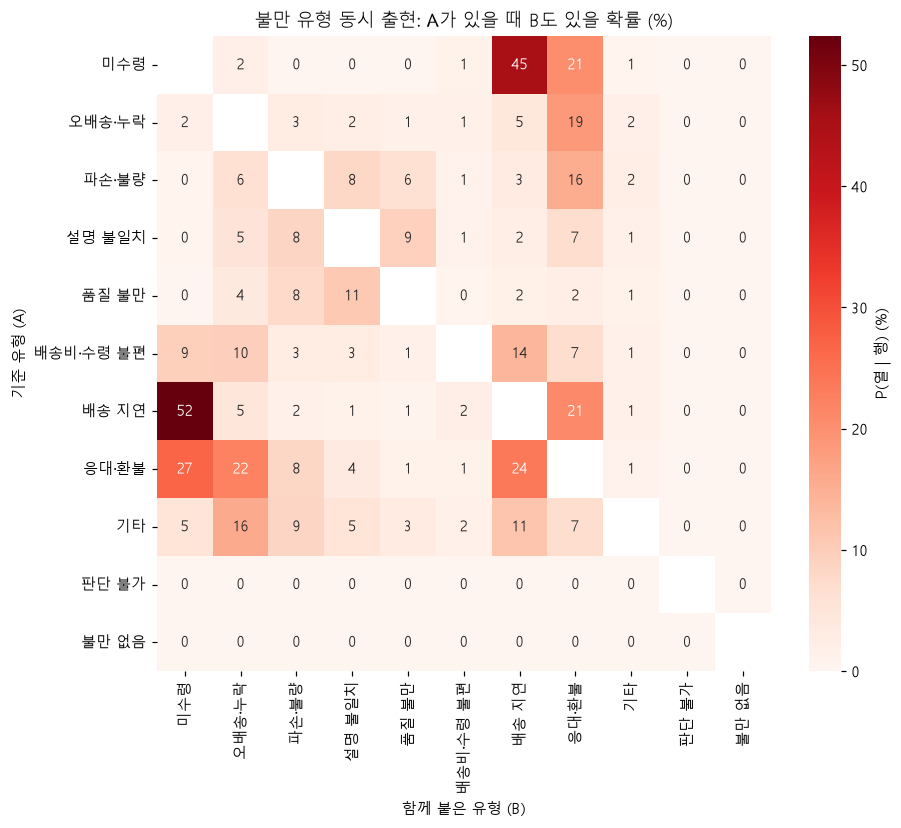

In [5]:
cooc = run_sql("q1_03_cooccurrence.sql")
cooc["A"] = cooc["label_a"].map(LABEL_KO)
cooc["B"] = cooc["label_b"].map(LABEL_KO)
top_pairs = cooc[cooc["ord_a"] < cooc["ord_b"]].sort_values("n_both", ascending=False).head(10)
display(top_pairs[["A", "B", "n_both", "p_b_given_a", "lift"]].assign(
    p_b_given_a=lambda d: (d["p_b_given_a"].astype(float) * 100).round(1).astype(str) + "%",
    lift=lambda d: d["lift"].astype(float).round(2)))

order = list(LABEL_KO.values())
heat = cooc.pivot(index="A", columns="B", values="p_b_given_a").reindex(index=order, columns=order).astype(float).fillna(0) * 100
fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(heat, annot=True, fmt=".0f", cmap="Reds", cbar_kws={"label": "P(열 | 행) (%)"}, ax=ax,
            mask=np.eye(len(heat), dtype=bool))  # 행·열 순서가 같으므로 대각선(자기 자신)은 가림
ax.set_xlabel("함께 붙은 유형 (B)")
ax.set_ylabel("기준 유형 (A)")
ax.set_title("불만 유형 동시 출현: A가 있을 때 B도 있을 확률 (%)")
save(fig, "q1_cooccurrence_heatmap.png")
plt.show()

## 4. 월별 추이

주문 월(구매 시각) 기준으로 개선 주체별 비중(주 원인 기준)을 본다. 분류 리뷰가 100건 미만인 달(`low_sample = 1`)은 차트에서 빼고 표에 표시한다.

100건 미만인 달: {'2016-09': 4, '2018-09': 3, '2018-10': 1}


,n_reviews,low_sample,물류,판매자 출고,상품,판매자 응대,플랫폼 정책,기타,불만 없음
order_month,,,,,,,,,
2016-09,4,1,100.0,0.0,0.0,0.0,0.0,0.0,0.0
2016-10,103,0,41.8,19.4,14.6,12.6,5.8,1.0,4.9
2017-01,129,0,32.6,18.6,26.4,7.0,3.9,1.6,10.1
2017-02,279,0,37.6,13.6,26.5,6.4,4.3,2.5,9.0
2017-03,379,0,33.0,17.7,27.2,8.4,1.8,3.4,8.4
2017-04,333,0,36.9,18.9,20.4,6.9,4.2,3.9,8.7
2017-05,476,0,25.2,21.2,30.0,6.7,2.5,6.5,7.8
2017-06,434,0,24.4,19.6,33.4,5.8,3.7,3.5,9.7
2017-07,515,0,24.3,17.9,28.2,8.0,3.9,4.5,13.4


저장: reports/figures/q1_monthly_owner_share.png


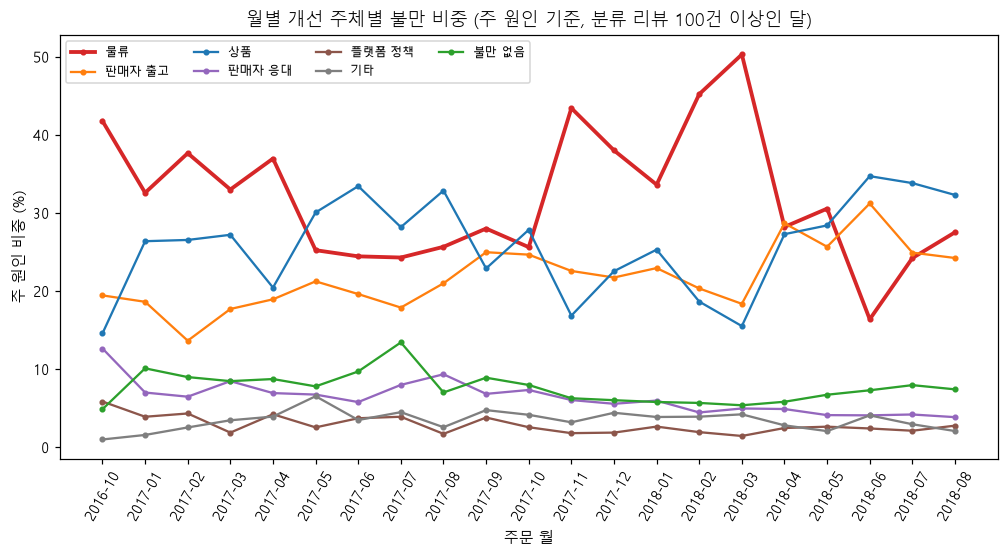

In [6]:
monthly = run_sql("q1_04_monthly_owner.sql")
month_n = monthly.groupby("order_month")[["n_reviews", "low_sample"]].first()
print("100건 미만인 달:", month_n[month_n["low_sample"] == 1]["n_reviews"].to_dict())

share = monthly.pivot(index="order_month", columns="owner", values="share_primary")[OWNER_ORDER].astype(float)
display(pd.concat([month_n, (share * 100).round(1)], axis=1))

plot_share = share[month_n["low_sample"] == 0] * 100
fig, ax = plt.subplots(figsize=(11, 5))
for owner in OWNER_ORDER:
    ax.plot(plot_share.index, plot_share[owner], marker="o", markersize=3, label=owner, color=OWNER_COLORS[owner],
            linewidth=2.5 if owner == "물류" else 1.5)
ax.set_xlabel("주문 월")
ax.set_ylabel("주 원인 비중 (%)")
ax.set_title("월별 개선 주체별 불만 비중 (주 원인 기준, 분류 리뷰 100건 이상인 달)")
ax.tick_params(axis="x", rotation=60)
ax.legend(ncol=4, fontsize=8, loc="upper left")
save(fig, "q1_monthly_owner_share.png")
plt.show()

### 보조: 물류 불만 비중과 실제 배송 지연율

리뷰 텍스트에서 나온 물류 불만 비중이 실제 배송 데이터(`v_orders`의 지연율, 배송 지표 제외 주문 빼고)와 같은 달에 함께 움직이는지 확인한다. 본격적인 분석은 Q2에서 한다.

In [7]:
late = run_sql("q1_08_monthly_late_rate.sql").set_index("order_month")
compare = pd.DataFrame({
    "물류 불만 비중(주 원인)": share["물류"],
    "실제 지연율": late["late_rate"].astype(float),
    "분류 리뷰 수": month_n["n_reviews"],
}).loc[month_n[month_n["low_sample"] == 0].index]
corr = compare["물류 불만 비중(주 원인)"].corr(compare["실제 지연율"])
print(f"월별 상관계수 (분류 리뷰 100건 이상인 {len(compare)}개월): {corr:.2f}")
display((compare[["물류 불만 비중(주 원인)", "실제 지연율"]] * 100).round(1).join(compare["분류 리뷰 수"]))

월별 상관계수 (분류 리뷰 100건 이상인 21개월): 0.74


,물류 불만 비중(주 원인),실제 지연율,분류 리뷰 수
order_month,,,
2016-10,41.8,0.8,103.0
2017-01,32.6,2.9,129.0
2017-02,37.6,3.0,279.0
2017-03,33.0,4.6,379.0
2017-04,36.9,6.6,333.0
2017-05,25.2,3.0,476.0
2017-06,24.4,3.0,434.0
2017-07,24.3,2.8,515.0
2017-08,25.6,2.9,472.0


## 5. 결제 후 품절·취소 주문 보완

LLM은 분류 체계 규칙 P에 따라 결제 후 품절 통보를 SERVICE로만 분류하는 경향이 있다(검증에서 NOT_RECEIVED 누락의 주요 원인).
주문 상태가 `unavailable`(결제 후 품절로 보임)·`canceled`인 리뷰를 확인하고, 주문 상태로 미수령을 보완했을 때 비중이 어떻게 바뀌는지 본다.

In [8]:
status = run_sql("q1_05_stockout_status.sql")
display(pct(status, ["share_not_received"]))

,status_group,n_reviews,n_not_received,share_not_received,n_no_complaint
0,unavailable,387,185.0,47.8%,4.0
1,canceled,345,158.0,45.8%,5.0
2,그 외,13554,3261.0,24.1%,998.0


NOT_RECEIVED가 붙지 않은 unavailable·canceled 리뷰의 주 원인:

In [9]:
stock_labels = run_sql("q1_06_stockout_labels.sql")
stock_labels["유형"] = stock_labels["primary_label"].map(LABEL_KO)
display(pct(stock_labels[["order_status", "유형", "n_reviews", "share_in_status", "n_with_service", "n_with_delay"]], ["share_in_status"]))

,order_status,유형,n_reviews,share_in_status,n_with_service,n_with_delay
0,unavailable,응대·환불,126,62.4%,126.0,0.0
1,unavailable,배송 지연,40,19.8%,20.0,40.0
2,unavailable,판단 불가,13,6.4%,0.0,0.0
3,unavailable,기타,8,4.0%,0.0,0.0
4,unavailable,불만 없음,4,2.0%,0.0,0.0
5,unavailable,파손·불량,4,2.0%,2.0,0.0
6,unavailable,품질 불만,3,1.5%,0.0,0.0
7,unavailable,오배송·누락,2,1.0%,0.0,1.0
8,unavailable,설명 불일치,2,1.0%,0.0,0.0
9,canceled,응대·환불,106,56.7%,106.0,0.0


보완 규칙: 대표 주문 상태가 unavailable·canceled이고 불만 없음(NO_COMPLAINT)이 아닌 리뷰는 미수령으로 간주한다. `after_unavailable`은 unavailable만 보완한 민감도 확인용이다(canceled에는 고객이 직접 취소한 주문이 섞여 있을 수 있음).

In [10]:
adjusted = run_sql("q1_07_stockout_adjusted.sql")
rates = adjusted[adjusted["ord"] <= 4].copy()
display(pct(rates[["metric", "before_adj", "after_both", "after_unavailable"]], ["before_adj", "after_both", "after_unavailable"]))
added = adjusted[adjusted["ord"] == 5].iloc[0]
print(f"보완으로 NOT_RECEIVED가 새로 붙은 리뷰: unavailable+canceled {int(added['after_both'])}건 / unavailable만 {int(added['after_unavailable'])}건")

,metric,before_adj,after_both,after_unavailable
0,NOT_RECEIVED 다중 라벨 비율,25.2%,27.9%,26.6%
1,NOT_RECEIVED 주 원인 비율,25.2%,27.9%,26.6%
2,물류(NOT_RECEIVED·DELAY) 다중 라벨 비율,35.6%,37.7%,36.7%
3,물류 주 원인 비율,33.9%,36.0%,35.0%


보완으로 NOT_RECEIVED가 새로 붙은 리뷰: unavailable+canceled 380건 / unavailable만 198건


## 정리

핵심 발견과 해석 주의점은 `reports/analysis/q1_complaint_causes.md`에 정리했다.